Using device: cpu

[2/7] Extracting features from trimmed signals...
 -> Extracted features from 300 signals

[3/7] Visualizing clean ECG signals with detected R-peaks...


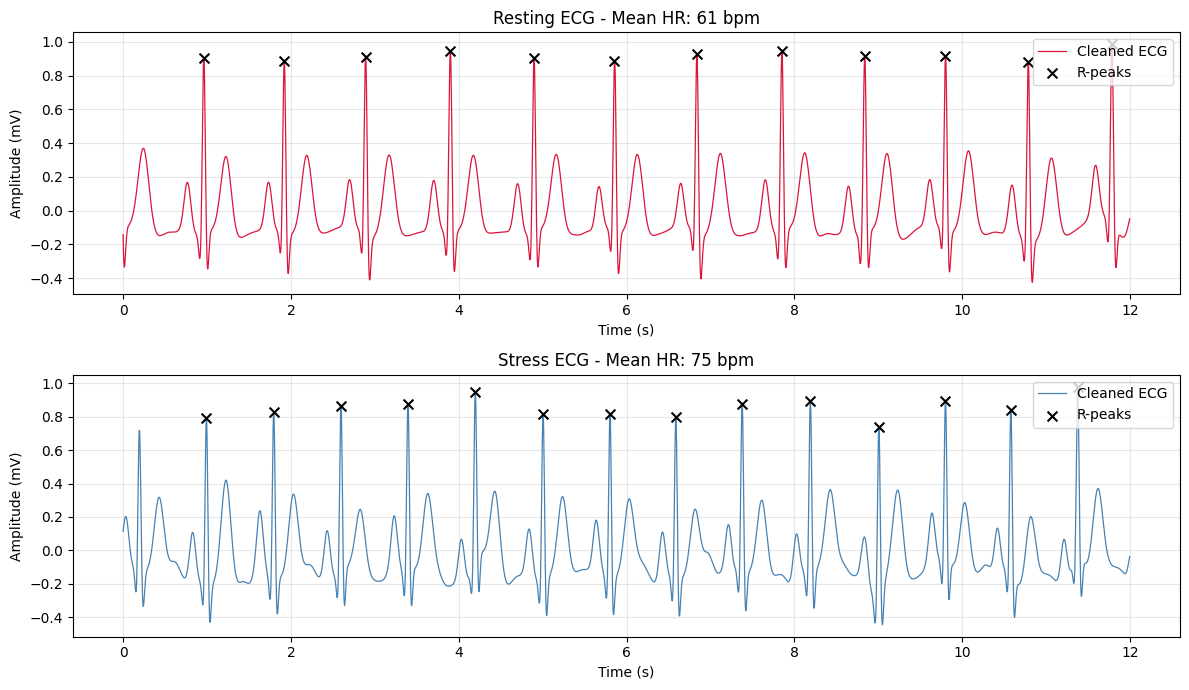


[4/7] Preprocessing and train/test split...
 -> Train: 225 samples, Test: 75 samples

[5/7] Training Random Forest...

[6/7] Training Classic ANN (PyTorch)...


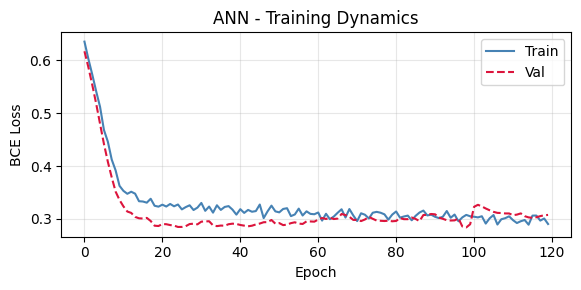


[7/7] Clinical evaluation...

--- Model Comparison ---
        Model  Accuracy  Precision (Stress)  Recall (Stress)   AUC
Random Forest     0.880               0.760            0.864 0.941
  Classic ANN     0.867               0.800            0.727 0.935


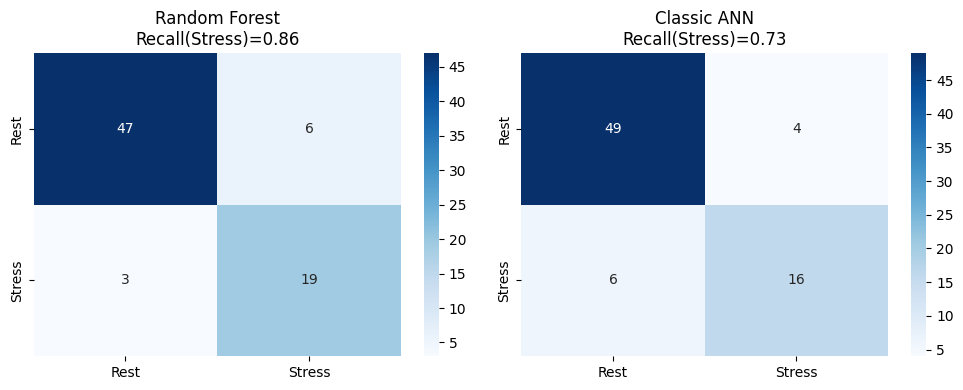

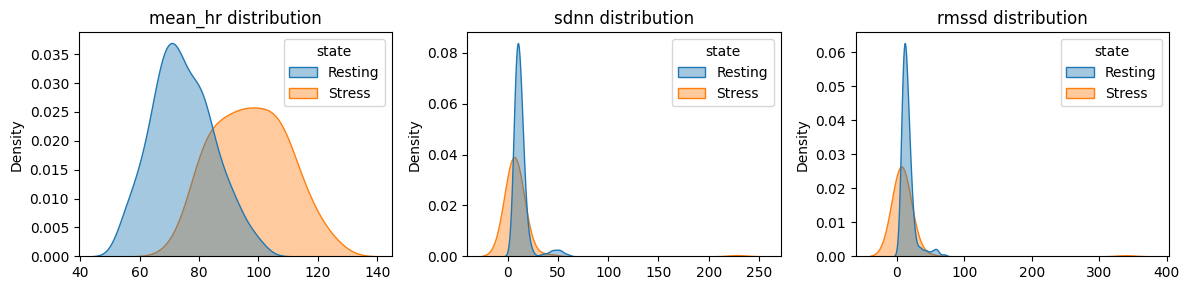


DISCUSSION POINTS FOR STUDENTS:

1) FILTER ARTIFACTS:
   - Bandpass filters create edge transients (first 2-3 seconds)
   - This is handled silently in the processing pipeline

2) REALISTIC CLASS OVERLAP:
   - Notice the overlapping distributions in mean_hr, sdnn, rmssd
   - Real clinical data is NEVER perfectly separable

3) WHY NOT 100% ACCURACY?
   - Perfect accuracy = red flag (overfitting or unrealistic data)
   - Real medical ML systems have 70-90% accuracy typically
   - The overlap forces models to make difficult decisions

4) RECALL vs PRECISION TRADE-OFF:
   - High Recall: Catch all stressed patients (but false alarms)
   - High Precision: Few false alarms (but miss some stressed patients)
   - Clinical context determines which is more important

5) MODEL DIFFERENCES:
   - Random Forest: Interpretable (feature importance), robust
   - ANN: Requires scaling, can learn complex patterns, extends to deep learning



In [4]:
# ==============================================================================
# LECTURE 1: AI & ML for Biosignals - ECG Classification
# ==============================================================================
# Requirements:
#   pip install neurokit2 scikit-learn matplotlib pandas numpy seaborn torch
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import neurokit2 as nk
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, recall_score,
                             precision_score, confusion_matrix, roc_curve, auc)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

SAMPLING_RATE = 250
SIGNAL_DURATION = 15  # Increased to allow trimming
TRIM_SECONDS = 3      # Discard first 3s to remove filter artifacts
OUTPUT_DIR = "ecg_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ==============================================================================
# PART 1: Simulating Raw ECG Signals
# ==============================================================================
def generate_ecg_cohort(n_rest=210, n_stress=90):
    """
    Generate a realistic clinical cohort with overlapping classes.
    """
    records = []
    
    # --- Resting state (label 0) ---
    for i in range(n_rest):
        if np.random.rand() < 0.10:  # 10% outliers
            hr = np.clip(np.random.normal(90, 8), 80, 100)
        else:
            hr = np.clip(np.random.normal(72, 10), 55, 95)
        
        noise = np.random.uniform(0.01, 0.08)
        if np.random.rand() < 0.05:
            noise += 0.1
        
        signal = nk.ecg_simulate(duration=SIGNAL_DURATION, sampling_rate=SAMPLING_RATE,
                                 heart_rate=hr, noise=noise, random_state=SEED + i)
        records.append(dict(signal=signal, label=0, state="Resting", 
                           true_hr=hr, noise_level=noise))

    # --- Stress state (label 1) ---
    for i in range(n_stress):
        if np.random.rand() < 0.10:  # 10% outliers
            hr = np.clip(np.random.normal(82, 6), 75, 92)
        else:
            hr = np.clip(np.random.normal(98, 12), 78, 125)
        
        noise = np.random.uniform(0.03, 0.10)
        if np.random.rand() < 0.10:
            noise += 0.15
        
        signal = nk.ecg_simulate(duration=SIGNAL_DURATION, sampling_rate=SAMPLING_RATE,
                                 heart_rate=hr, noise=noise, random_state=SEED + n_rest + i)
        records.append(dict(signal=signal, label=1, state="Stress",
                           true_hr=hr, noise_level=noise))

    return pd.DataFrame(records)

df_signals = generate_ecg_cohort()
df_signals.to_pickle(f"{OUTPUT_DIR}/ecg_signals_full.pkl")

# ==============================================================================
# PART 2: Signal Processing & Feature Extraction
# ==============================================================================
# DISCUSSION POINT: Why trim the beginning of the signal?
# Bandpass filters introduce edge artifacts (transients). In real analysis,
# we must discard the first few seconds before feature extraction.

def extract_ecg_features(signal, fs=SAMPLING_RATE, trim_s=TRIM_SECONDS):
    """
    Extract HRV features from ECG signal after trimming filter artifacts.
    Process: Clean -> Trim -> Detect Peaks -> Extract Features
    """
    try:
        # Step 1: Clean the signal (bandpass 0.5-40 Hz)
        cleaned = nk.ecg_clean(signal, sampling_rate=fs)
        
        # Step 2: Trim the first N seconds to remove filter edge effects
        trim_samples = int(trim_s * fs)
        cleaned_trimmed = cleaned[trim_samples:]
        
        # Step 3: Detect R-peaks on trimmed signal
        peaks, info = nk.ecg_peaks(cleaned_trimmed, sampling_rate=fs)
        
        # Step 4: Check if we have enough beats for HRV analysis
        if len(info['ECG_R_Peaks']) < 3:
            return {k: np.nan for k in ("mean_hr", "std_hr", "sdnn", "rmssd", "mean_nn")}
        
        # Step 5: Compute heart rate and HRV
        rate = nk.ecg_rate(peaks, sampling_rate=fs)
        hrv = nk.hrv_time(peaks, sampling_rate=fs, show=False)
        
        return {
            "mean_hr": float(rate.mean()),
            "std_hr": float(rate.std()),
            "sdnn": float(hrv["HRV_SDNN"].iloc[0]),
            "rmssd": float(hrv["HRV_RMSSD"].iloc[0]),
            "mean_nn": float(hrv["HRV_MeanNN"].iloc[0])
        }
    except Exception:
        return {k: np.nan for k in ("mean_hr", "std_hr", "sdnn", "rmssd", "mean_nn")}

print("\n[2/7] Extracting features from trimmed signals...")
features_list = []
for idx, row in df_signals.iterrows():
    feats = extract_ecg_features(row.signal)
    feats["label"] = row["label"]
    feats["state"] = row["state"]
    feats["true_hr"] = row["true_hr"]
    feats["subject_id"] = f"{row['state'][0]}{idx:03d}"
    features_list.append(feats)

df_features = pd.DataFrame(features_list).dropna().reset_index(drop=True)
df_features.to_csv(f"{OUTPUT_DIR}/ecg_features.csv", index=False)
FEATURE_COLS = ["mean_hr", "std_hr", "sdnn", "rmssd", "mean_nn"]

print(f" -> Extracted features from {len(df_features)} signals")

# ==============================================================================
# PART 3: Visualization (Clean signals with R-peaks)
# ==============================================================================
print("\n[3/7] Visualizing clean ECG signals with detected R-peaks...")

def get_clean_trimmed_signal(signal, fs=SAMPLING_RATE, trim_s=TRIM_SECONDS):
    """Helper to get clean, trimmed signal and peaks for visualization."""
    cleaned = nk.ecg_clean(signal, sampling_rate=fs)
    trim_samples = int(trim_s * fs)
    cleaned_trimmed = cleaned[trim_samples:]
    peaks, info = nk.ecg_peaks(cleaned_trimmed, sampling_rate=fs)
    time = np.arange(len(cleaned_trimmed)) / fs
    return time, cleaned_trimmed, info['ECG_R_Peaks']

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, label_val, color, title in zip(axes, [0, 1], ["crimson", "steelblue"], 
                                        ["Resting ECG", "Stress ECG"]):
    subset = df_signals[df_signals.label == label_val]
    row = subset.iloc[0]
    
    time, sig_trimmed, r_peaks = get_clean_trimmed_signal(row.signal)
    
    ax.plot(time, sig_trimmed, color=color, lw=0.9, label='Cleaned ECG')
    ax.scatter(time[r_peaks], sig_trimmed[r_peaks], 
               color='black', marker='x', s=50, label='R-peaks', zorder=5)
    ax.set_title(f"{title} - Mean HR: {row['true_hr']:.0f} bpm")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude (mV)")
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==============================================================================
# PART 4: Preprocessing & Split
# ==============================================================================
print("\n[4/7] Preprocessing and train/test split...")

X = df_features[FEATURE_COLS].values
y = df_features["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

# DISCUSSION POINT: Standardization is CRITICAL for neural networks
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f" -> Train: {len(X_train)} samples, Test: {len(X_test)} samples")

# ==============================================================================
# PART 5: Random Forest
# ==============================================================================
print("\n[5/7] Training Random Forest...")

rf = RandomForestClassifier(n_estimators=100, max_depth=5, 
                            class_weight="balanced", random_state=SEED)
rf.fit(X_train_s, y_train)
y_pred_rf = rf.predict(X_test_s)
y_prob_rf = rf.predict_proba(X_test_s)[:, 1]

# ==============================================================================
# PART 6: Classic Artificial Neural Network (PyTorch)
# ==============================================================================
print("\n[6/7] Training Classic ANN (PyTorch)...")

class ClassicANN(nn.Module):
    """Simple feedforward network for binary classification."""
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 16),        nn.ReLU(),
            nn.Linear(16, 1),         nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

X_tr_t = torch.tensor(X_train_s, dtype=torch.float32)
y_tr_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_test_s, dtype=torch.float32)
y_te_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=16, shuffle=True)

model = ClassicANN(input_dim=X_train_s.shape[1]).to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 120
train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * xb.size(0)
    train_losses.append(epoch_loss / len(X_tr_t))
    
    model.eval()
    with torch.no_grad():
        val_losses.append(criterion(model(X_te_t.to(device)), y_te_t.to(device)).item())

model.eval()
with torch.no_grad():
    y_prob_ann = model(X_te_t.to(device)).cpu().numpy().ravel()
y_pred_ann = (y_prob_ann >= 0.5).astype(int)

# Plot training curves
plt.figure(figsize=(6, 3))
plt.plot(train_losses, label="Train", color="steelblue")
plt.plot(val_losses, label="Val", color="crimson", linestyle="--")
plt.title("ANN - Training Dynamics")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==============================================================================
# PART 7: Clinical Evaluation
# ==============================================================================
print("\n[7/7] Clinical evaluation...")

def evaluate_model(y_true, y_pred, y_prob, name):
    return {"Model": name, 
            "Accuracy": np.mean(y_true == y_pred),
            "Precision (Stress)": precision_score(y_true, y_pred, pos_label=1),
            "Recall (Stress)": recall_score(y_true, y_pred, pos_label=1),
            "AUC": auc(*roc_curve(y_true, y_prob)[:2])}

results = pd.DataFrame([
    evaluate_model(y_test, y_pred_rf, y_prob_rf, "Random Forest"),
    evaluate_model(y_test, y_pred_ann, y_prob_ann, "Classic ANN")
])

print("\n--- Model Comparison ---")
print(results.to_string(index=False, float_format="%.3f"))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, y_pred, name in zip(axes, [y_pred_rf, y_pred_ann], 
                            ["Random Forest", "Classic ANN"]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Rest', 'Stress'], yticklabels=['Rest', 'Stress'])
    recall = recall_score(y_test, y_pred, pos_label=1)
    ax.set_title(f"{name}\nRecall(Stress)={recall:.2f}")
plt.tight_layout()
plt.show()

# Feature distributions (showing overlap)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, feat in zip(axes, ["mean_hr", "sdnn", "rmssd"]):
    sns.kdeplot(data=df_features, x=feat, hue="state", fill=True, 
                alpha=0.4, ax=ax, common_norm=False)
    ax.set_title(f"{feat} distribution")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# ==============================================================================
# DISCUSSION POINTS
# ==============================================================================
print("\n" + "=" * 70)
print("DISCUSSION POINTS FOR STUDENTS:")
print("=" * 70)
print("""
1) FILTER ARTIFACTS:
   - Bandpass filters create edge transients (first 2-3 seconds)
   - This is handled silently in the processing pipeline

2) REALISTIC CLASS OVERLAP:
   - Notice the overlapping distributions in mean_hr, sdnn, rmssd
   - Real clinical data is NEVER perfectly separable

3) WHY NOT 100% ACCURACY?
   - Perfect accuracy = red flag (overfitting or unrealistic data)
   - Real medical ML systems have 70-90% accuracy typically
   - The overlap forces models to make difficult decisions

4) RECALL vs PRECISION TRADE-OFF:
   - High Recall: Catch all stressed patients (but false alarms)
   - High Precision: Few false alarms (but miss some stressed patients)
   - Clinical context determines which is more important

5) MODEL DIFFERENCES:
   - Random Forest: Interpretable (feature importance), robust
   - ANN: Requires scaling, can learn complex patterns, extends to deep learning
""")
print("=" * 70)